**Modelos: árbol de decisión, kNN y Random Forest**

**Objetivo:** ajustar los hiperparámetros de cada modelo con el código común del grupo (mismos datos, mismos folds, mismas métricas y mismo Pipeline), analizar el sobreajuste y guardar los resultados para compararlos con los del resto del grupo.

El conjunto de test no se usa en este notebook: se evalúa una sola vez al final, con el modelo elegido entre todos los del grupo.

# Librerías

In [1]:
import time

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 1. Datos

Se cargan los datos preparados en el EDA (limpios y codificados, con sus nulos) con la partición 80/20 estratificada común. A partir de aquí solo se usan `X_train` e `y_train`.

In [2]:
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de clases en train:", y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30) | Test: (451, 30)
Proporción de clases en train: {0: 0.5, 1: 0.3, 2: 0.2}


**Curvas de validación.** La tabla de resultados solo muestra la diferencia entre train y validación de la mejor combinación. Para justificar esa elección frente a las demás, se mueve un hiperparámetro, se dejan los demás en su mejor valor y se representan train y validación (media ± desviación entre folds). Si el train mejora y la validación no, el modelo está memorizando en lugar de generalizar.

In [3]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Train y validación (media ± desviación) al mover un hiperparámetro, con el resto en su mejor valor."""
    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train, y_train,
        param_name=parametro, param_range=valores,
        cv=mod.validador, scoring=mod.metrica,      # mismos folds y misma métrica que la búsqueda
        std_display_style="fill_between", n_jobs=-1)
    plt.title(titulo)
    plt.ylabel("F1 macro")                         # en la leyenda, "Test" es el fold de validación
    plt.show()

# 2. Experimento de balanceo

Antes de ajustar los modelos se comprueba qué técnica de balanceo conviene. Se comparan tres opciones con varias métricas:

- **Sin balancear:** la referencia, para saber si balancear aporta algo.
- **`class_weight="balanced"`:** aprendizaje sensible al coste; da más peso a los errores en las clases minoritarias.
- **SMOTENC:** genera pacientes sintéticos de las clases minoritarias sin inventar valores en las variables binarias y categóricas.

El experimento se hace con el árbol y con kNN. Cada opción se ajusta con la misma rejilla de hiperparámetros, para que la comparación sea justa. Las búsquedas con SMOTENC se reutilizan después en las secciones 3 y 4.

In [4]:
# rejillas que se usan aquí y en las secciones 3 y 4
rejilla_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 5, 8, 12, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}
rejilla_knn = {
    "modelo__n_neighbors": [3, 5, 11, 21, 31, 51, 75],
    "modelo__metric": ["euclidean", "manhattan"],   # distancia en línea recta o sumando las diferencias de cada variable
}

busquedas_arbol, busquedas_knn, tablas_balanceo = {}, {}, []

# árbol: las tres opciones
for balanceo in [None, "class_weight", "smotenc"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(DecisionTreeClassifier(random_state=cte.semilla), balanceo=balanceo), rejilla_arbol)
    busquedas_arbol[balanceo] = busqueda.fit(X_train, y_train)
    tablas_balanceo.append(mod.tabla_resultados(busqueda, f"árbol | {balanceo}"))

# kNN no admite class_weight: solo sin balancear y con SMOTENC
for balanceo in [None, "smotenc"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(KNeighborsClassifier(), balanceo=balanceo), rejilla_knn)
    busquedas_knn[balanceo] = busqueda.fit(X_train, y_train)
    tablas_balanceo.append(mod.tabla_resultados(busqueda, f"kNN | {balanceo}"))

balanceo_resultados = pd.concat(tablas_balanceo)
balanceo_resultados[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
 "precision_alto_val", "diferencia_train_val", "mejores_parametros"]].round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
árbol | None,0.545,0.010,0.504,0.028,0.552,0.117,"{'modelo__criterion': 'entropy', 'modelo__max_..."
árbol | class_weight,0.532,0.022,0.596,0.038,0.460,0.147,"{'modelo__criterion': 'gini', 'modelo__max_dep..."
árbol | smotenc,0.541,0.033,0.596,0.020,0.504,0.326,"{'modelo__criterion': 'entropy', 'modelo__max_..."
kNN | None,0.537,0.022,0.410,0.050,0.802,0.032,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."
kNN | smotenc,0.590,0.020,0.773,0.069,0.562,0.045,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."


**Conclusión.**

- **Balancear mejora claramente la métrica crítica.** En el árbol, el recall de riesgo alto sube de 0,50 a 0,60 tanto con `class_weight` como con SMOTENC. En kNN la mejora es mayor: de 0,41 a 0,77.
- **El coste es una menor precisión de riesgo alto** (en kNN, de 0,80 a 0,56), es decir, más falsas alarmas. Desde el punto de vista clínico compensa: no detectar a un paciente de riesgo alto es más grave que hacer pruebas innecesarias a uno que no lo es.
- **El F1 macro no empeora:** en el árbol las tres opciones empatan (entre 0,532 y 0,545, dentro de la desviación entre folds) y en kNN sube de 0,537 a 0,590.
- **Entre `class_weight` y SMOTENC**, en el árbol el recall de riesgo alto es el mismo, pero SMOTENC obtiene algo más de precisión (0,504 frente a 0,460). Además, SMOTENC se puede aplicar a todos los modelos y `class_weight` no (kNN no lo admite). Por eso se elige **SMOTENC** para el resto de modelos.
- El árbol con SMOTENC sobreajusta más (diferencia train-validación de 0,33 frente a 0,12 sin balancear), porque la búsqueda elige un árbol más profundo. Se analiza en la sección 3.

# 3. Árbol de decisión

Primero se entrena un árbol sencillo para ver su tamaño y después se busca la mejor combinación de hiperparámetros:

- `criterion`: medida de la pureza de los nodos (`gini` o `entropy`).
- `max_depth`: profundidad máxima. A mayor profundidad, más se ajusta al train y mayor es el riesgo de sobreajuste.
- `min_samples_leaf`: número mínimo de pacientes por hoja. Cuanto mayor, más sencillo es el árbol.

No se incluye `min_samples_split` (pacientes mínimos para dividir un nodo): con 5 o más pacientes por hoja, los valores 2 y 10 daban exactamente el mismo resultado, así que no aportaba nada.

In [5]:
# árbol de partida, sin ajustar
arbol = mod.crear_pipeline(DecisionTreeClassifier(max_depth=5, criterion="gini", random_state=cte.semilla))
arbol.fit(X_train, y_train)

print(f"Profundidad del árbol: {arbol.named_steps['modelo'].get_depth()}")
print(f"Número de nodos terminales: {arbol.named_steps['modelo'].get_n_leaves()}")

Profundidad del árbol: 5
Número de nodos terminales: 27


In [6]:
# la búsqueda con SMOTENC ya está hecha en el experimento de balanceo
busqueda_arbol = busquedas_arbol["smotenc"]

mejor_arbol = busqueda_arbol.best_estimator_.named_steps["modelo"]
print("Mejores parámetros:", busqueda_arbol.best_params_)
print(f"Profundidad del árbol: {mejor_arbol.get_depth()}")
print(f"Número de nodos terminales: {mejor_arbol.get_n_leaves()}")

Mejores parámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
Profundidad del árbol: 17
Número de nodos terminales: 268


In [7]:
tabla_arbol = mod.tabla_resultados(busqueda_arbol, "arbol")
mod.guardar_resultados(busqueda_arbol, "arbol")
tabla_arbol.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
arbol,0.867,0.003,0.541,0.033,0.866,0.003,0.537,0.033,0.869,0.004,...,0.872,0.016,0.596,0.02,0.862,0.015,0.504,0.033,0.326,"{'modelo__criterion': 'entropy', 'modelo__max_..."


Las 5 mejores combinaciones, con su F1 en train, para comprobar si alguna es casi igual de buena pero sobreajusta menos:

In [8]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
resultados_arbol[["param_modelo__criterion", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
                  "mean_train_f1_macro", "mean_test_f1_macro", "std_test_f1_macro"]] \
    .sort_values("mean_test_f1_macro", ascending=False).head(5).round(3)

,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro
28,entropy,None,5,0.867,0.541,0.033
11,gini,12,20,0.693,0.540,0.008
14,gini,None,20,0.693,0.540,0.008
8,gini,8,20,0.676,0.534,0.014
29,entropy,None,20,0.692,0.533,0.015


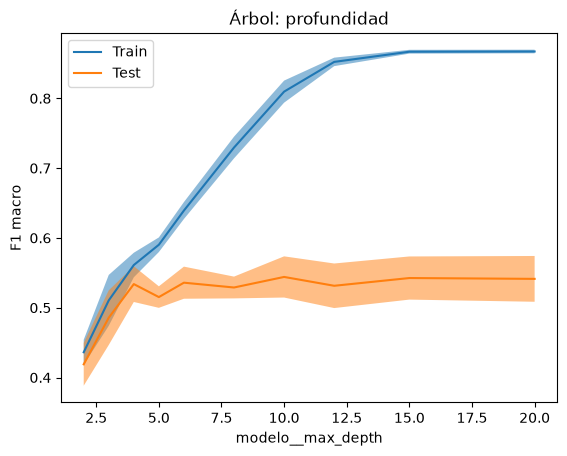

In [9]:
curva_validacion(busqueda_arbol, "modelo__max_depth", [2, 3, 4, 5, 6, 8, 10, 12, 15, 20], "Árbol: profundidad")

**Primeras decisiones del árbol.** Se representan solo los 3 primeros niveles, que sirven para comparar su interpretabilidad con la de kNN y Random Forest, que no se pueden leer de esta forma.

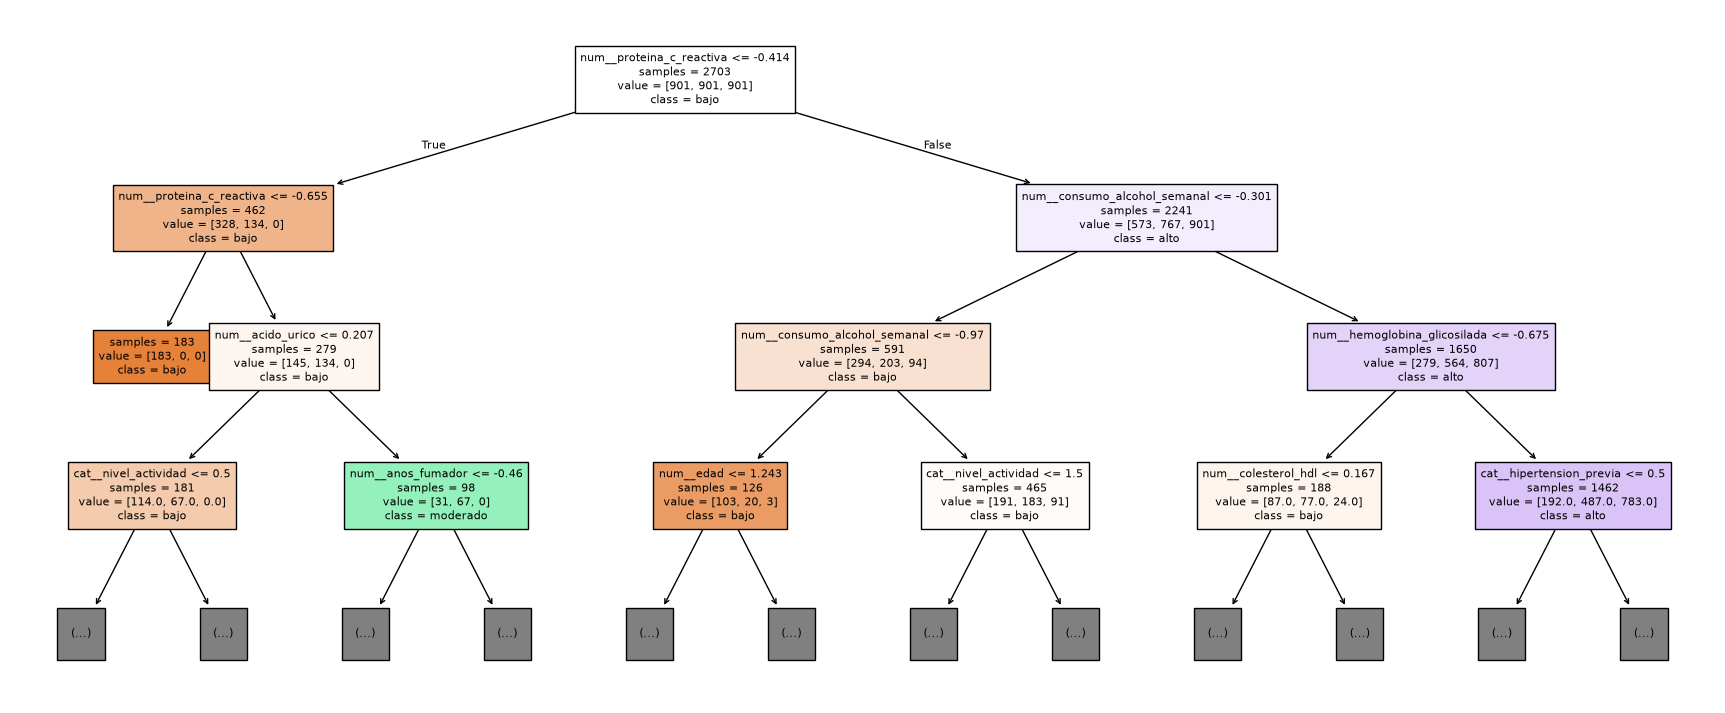

In [10]:
nombres_arbol = busqueda_arbol.best_estimator_.named_steps["preprocesado"].get_feature_names_out()

plt.figure(figsize=(22, 9))
plot_tree(mejor_arbol, max_depth=3, feature_names=nombres_arbol, class_names=["bajo", "moderado", "alto"],
          filled=True, impurity=False, fontsize=8)
plt.show()

**Conclusión.**

- **La mejor combinación** es `entropy`, sin límite de profundidad y 5 pacientes por hoja: un árbol de 17 niveles y 268 hojas, con un F1 macro de 0,541 ± 0,033 en validación y un recall de riesgo alto de 0,60.
- **Presenta un sobreajuste importante:** 0,867 en train frente a 0,541 en validación. La curva de validación lo confirma: a partir de la profundidad 4 la validación oscila entre 0,51 y 0,54, mientras que el train sigue subiendo hasta 0,87. La profundidad adicional solo sirve para memorizar pacientes del train.
- **Existe una alternativa igual de buena y más sencilla:** `gini`, profundidad 12 y 20 pacientes por hoja obtiene 0,540 ± 0,008 en validación (un empate), pero solo 0,693 en train y la mitad de variación entre folds. Si se eligiera el árbol, sería preferible esta combinación, porque generaliza igual con menos sobreajuste.
- **Es el modelo más interpretable:** las primeras divisiones usan la proteína C reactiva, el consumo de alcohol y la hemoglobina glicosilada, las mismas variables que el EDA señaló como más relacionadas con el riesgo. Hay dos matices: los umbrales están en unidades escaladas (por el `RobustScaler`), no en mg/L, y los recuentos de la raíz incluyen los pacientes sintéticos de SMOTENC.
- **Es el que peor rendimiento tiene de los tres:** de los 361 pacientes de riesgo alto del train, 37 (un 10 %) se clasifican como riesgo bajo, que es el error más grave.

# 4. kNN (k vecinos más cercanos)

kNN clasifica a cada paciente según la clase de sus `n_neighbors` vecinos más cercanos. Con pocos vecinos el modelo es muy flexible y se ajusta al ruido del train (sobreajuste); con muchos, se vuelve demasiado simple (subajuste).

Como se basa en distancias, necesita las variables escaladas, de lo que se encarga el `RobustScaler` del Pipeline.

In [11]:
# la búsqueda con SMOTENC ya está hecha en el experimento de balanceo (rejilla_knn)
busqueda_knn = busquedas_knn["smotenc"]
print("Mejores parámetros:", busqueda_knn.best_params_)

Mejores parámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 51}


In [12]:
tabla_knn = mod.tabla_resultados(busqueda_knn, "knn")
mod.guardar_resultados(busqueda_knn, "knn")
tabla_knn.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
knn,0.635,0.015,0.59,0.02,0.641,0.014,0.598,0.021,0.669,0.013,...,0.851,0.017,0.773,0.069,0.606,0.029,0.562,0.04,0.045,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."


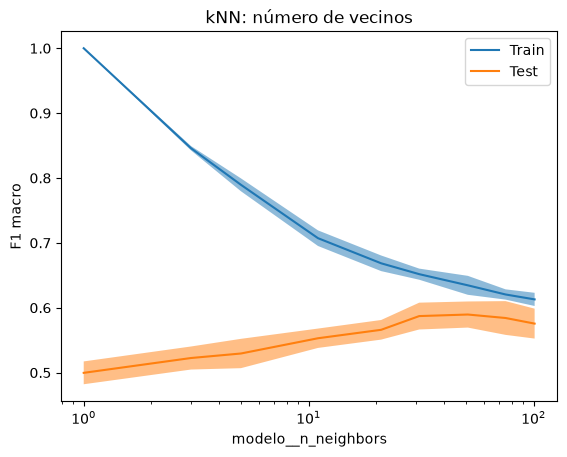

In [13]:
curva_validacion(busqueda_knn, "modelo__n_neighbors", [1, 3, 5, 11, 21, 31, 51, 75, 101], "kNN: número de vecinos")

**Conclusión.**

- **La mejor combinación** son 51 vecinos con distancia Manhattan: F1 macro de 0,590 ± 0,020 en validación y el **mejor recall de riesgo alto de los tres modelos (0,77)**.
- **Apenas sobreajusta:** 0,635 en train frente a 0,590 en validación (diferencia de 0,045).
- **La curva de validación refleja el compromiso entre sesgo y varianza:** con 1 vecino el train es perfecto (1,0) y la validación se queda en 0,50, porque el modelo memoriza a cada paciente. Al aumentar los vecinos, el train baja y la validación sube hasta estabilizarse entre 31 y 51; con 75 o más empieza a bajar (subajuste). El valor elegido, 51, queda dentro de la rejilla y no en un extremo.
- **Comete muy pocos errores graves:** de los 361 pacientes de riesgo alto, solo 8 (un 2 %) se clasifican como riesgo bajo, y 74 como moderado.
- **A cambio, genera muchas falsas alarmas:** clasifica como moderado al 39 % de los pacientes de riesgo bajo y como alto al 30 % de los moderados. Su precisión de riesgo alto (0,56) queda lejos de la de Random Forest (0,65).

# 5. Random Forest

Random Forest es un ensemble de tipo **bagging**: entrena muchos árboles, cada uno con una muestra bootstrap de los pacientes y con un subconjunto aleatorio de variables en cada división, y combina sus predicciones por votación. Al promediar árboles distintos reduce la varianza (el sobreajuste) de un único árbol.

- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima de cada árbol.
- `max_features`: número de variables que se prueban en cada división. Cuantas menos, más distintos son los árboles entre sí.
- `min_samples_leaf`: número mínimo de pacientes por hoja. Limita cuánto memoriza cada árbol.

No se usa el error OOB para ajustarlo: dentro del Pipeline los árboles también ven pacientes sintéticos de SMOTENC, y además así se valida con el mismo esquema que el resto del grupo.

In [14]:
rejilla_rf = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [5, 10, None],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__min_samples_leaf": [1, 5, 10],
}

busqueda_rf = mod.crear_busqueda(mod.crear_pipeline(RandomForestClassifier(random_state=cte.semilla)), rejilla_rf)
busqueda_rf.fit(X_train, y_train)
print("Mejores parámetros:", busqueda_rf.best_params_)

Mejores parámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}


In [15]:
tabla_rf = mod.tabla_resultados(busqueda_rf, "random_forest")
mod.guardar_resultados(busqueda_rf, "random_forest")
tabla_rf.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
random_forest,1.0,0.0,0.627,0.023,1.0,0.0,0.625,0.025,1.0,0.0,...,1.0,0.0,0.69,0.027,1.0,0.0,0.653,0.045,0.373,"{'modelo__max_depth': None, 'modelo__max_featu..."


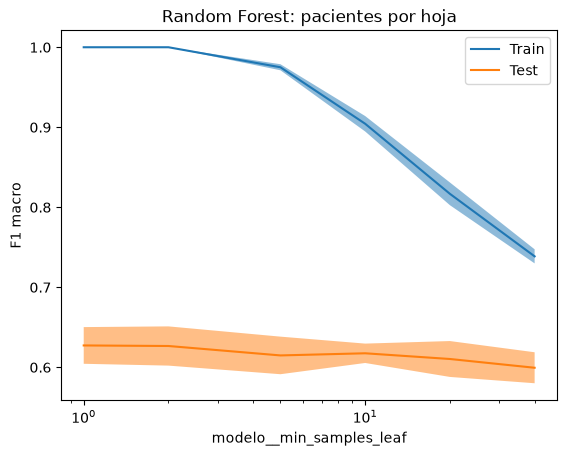

In [16]:
curva_validacion(busqueda_rf, "modelo__min_samples_leaf", [1, 2, 5, 10, 20, 40], "Random Forest: pacientes por hoja")

**Importancia de las variables.** Random Forest permite estimar qué variables utiliza más para decidir. Se analiza de dos formas:

- **Por impureza** (`feature_importances_`): cuánto mejora cada variable la pureza de los nodos. Es rápida, pero favorece a las variables continuas con muchos valores distintos.
- **Por permutación** (`permutation_importance`): cuánto empeora el F1 macro al desordenar cada variable. Se calcula en cada fold de **validación** y no en train, porque el Random Forest obtiene un F1 de 1 en train (memoriza a los pacientes): al desordenar una variable, las demás compensan su pérdida y casi todas aparecerían con importancia nula.

In [17]:
rf = busqueda_rf.best_estimator_.named_steps["modelo"]

# nombres de las variables a la salida del preprocesado (salen con prefijo, p. ej. "num__edad")
nombres = busqueda_rf.best_estimator_.named_steps["preprocesado"].get_feature_names_out()

importancia_impureza = pd.Series(rf.feature_importances_, index=nombres).sort_values(ascending=False)
importancia_impureza.head(10).round(3)

num__proteina_c_reactiva             0.097
num__consumo_alcohol_semanal         0.085
num__hemoglobina_glicosilada         0.069
num__acido_urico                     0.048
num__clearance_creatinina            0.046
num__glucosa_ayunas                  0.044
num__indice_masa_corporal            0.042
num__frecuencia_ejercicio_semanal    0.042
num__colesterol_hdl                  0.039
num__presion_sistolica               0.038
dtype: float64

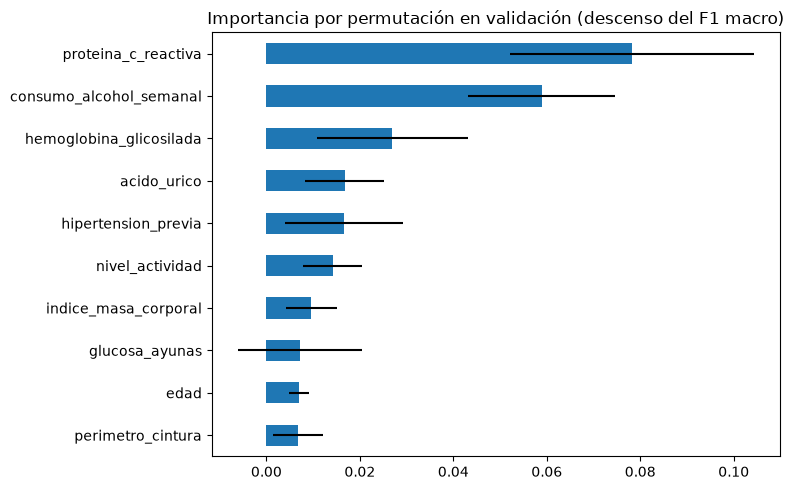

In [18]:
importancias = []
for idx_train, idx_val in mod.validador.split(X_train, y_train):
    # se entrena con 4 folds y se permuta sobre el fold que el modelo no ha visto
    modelo = clone(busqueda_rf.best_estimator_).fit(X_train.iloc[idx_train], y_train.iloc[idx_train])
    perm = permutation_importance(modelo, X_train.iloc[idx_val], y_train.iloc[idx_val], scoring=mod.metrica,
                                  n_repeats=10, random_state=cte.semilla, n_jobs=-1)
    importancias.append(perm.importances_mean)

importancias = pd.DataFrame(importancias, columns=X_train.columns)
top = importancias.mean().sort_values(ascending=False).head(10)
top.plot.barh(xerr=importancias[top.index].std(), figsize=(8, 5)).invert_yaxis()   # barra = media ± desviación entre folds
plt.title("Importancia por permutación en validación (descenso del F1 macro)")
plt.tight_layout()
plt.show()

**Conclusión.**

- **La mejor combinación** son 300 árboles sin límite de profundidad, `max_features="sqrt"` y 1 paciente por hoja: **el mejor F1 macro de los tres (0,627 ± 0,023)**, con un recall de riesgo alto de 0,69 y la mejor precisión de riesgo alto (0,65).
- **Obtiene un 1,0 en train porque cada árbol memoriza a los pacientes,** pero aun así es el que mejor generaliza: 0,086 más en validación que el árbol individual. Es el comportamiento esperado del bagging: cada árbol sobreajusta por separado, pero al promediar muchos árboles distintos se reduce la varianza.
- **Limitar los pacientes por hoja no mejora el resultado:** según la curva de validación, al aumentar `min_samples_leaf` el train baja de 1,0 a 0,74, pero la validación se mantiene entre 0,60 y 0,63. Se reduce el sobreajuste, pero no mejora la generalización.
- **Importancia de las variables:** por permutación en validación, las más relevantes son la proteína C reactiva (0,078 ± 0,026), el consumo de alcohol (0,059 ± 0,016) y la hemoglobina glicosilada (0,027 ± 0,016), seguidas a distancia por el ácido úrico, la hipertensión previa y el nivel de actividad. Coincide con el EDA, donde esas tres eran las más relacionadas con el riesgo (Spearman: alcohol 0,39, hemoglobina glicosilada 0,28 y proteína C reactiva 0,28).
- **Variables con poca importancia:** el colesterol (total, HDL y LDL), los triglicéridos, el uso de antihipertensivos, la frecuencia de ejercicio y los antecedentes familiares tienen una importancia por permutación dentro del ruido entre folds (por ejemplo, el HDL: 0,002 ± 0,014). Esto no significa que no estén relacionadas con el riesgo: en el EDA lo estaban el HDL (Spearman −0,20), el uso de antihipertensivos (0,24) y el ejercicio (−0,21), y en los antecedentes el riesgo alto pasaba del 12 % (ninguno) al 40 % (ambos). Significa que el modelo apenas pierde F1 cuando se desordenan, probablemente porque su efecto es pequeño frente al de la proteína C reactiva, el alcohol y la hemoglobina glicosilada.

# 6. Comparación de los modelos

Se reúnen las tablas de los tres modelos. El criterio de elección es el F1 macro y, si dos modelos quedan dentro de la desviación entre folds, el recall de riesgo alto. Se añade el tiempo de entrenamiento como medida de complejidad, y una comparación fold a fold. El tiempo se mide entrenando cada modelo con todo el train y no con `mean_fit_time` de la búsqueda, que incluye el arranque de los procesos en paralelo y varía mucho de una ejecución a otra.

In [19]:
busquedas = {"arbol": busqueda_arbol, "knn": busqueda_knn, "random_forest": busqueda_rf}

comparacion = pd.concat([tabla_arbol, tabla_knn, tabla_rf])
def tiempo_entrenamiento(busqueda, repeticiones=3):
    """Segundos que tarda en entrenarse la mejor combinación con todo el train (el mínimo de varias repeticiones)."""
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        clone(busqueda.best_estimator_).fit(X_train, y_train)
        tiempos.append(time.perf_counter() - inicio)
    return min(tiempos)   # el mínimo es el más estable: los demás incluyen interrupciones del sistema

comparacion["tiempo_entrenamiento_s"] = [tiempo_entrenamiento(b) for b in busquedas.values()]
comparacion[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
             "precision_alto_val", "diferencia_train_val", "tiempo_entrenamiento_s"]] \
    .sort_values("f1_macro_val", ascending=False).round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,tiempo_entrenamiento_s
modelo,,,,,,,
random_forest,0.627,0.023,0.690,0.027,0.653,0.373,2.211
knn,0.590,0.020,0.773,0.069,0.562,0.045,0.286
arbol,0.541,0.033,0.596,0.020,0.504,0.326,0.344


**Comparación fold a fold.** Comparar la diferencia de medias con la desviación de cada modelo es poco riguroso. Como todos los modelos se validan con los mismos folds, se pueden comparar por pares: en cada fold, la diferencia de F1 macro entre Random Forest y kNN. Es el tipo de comparación que formaliza el test estadístico opcional.

In [20]:
folds = pd.DataFrame({n: pd.read_csv(mod.RUTA_RESULTADOS / f"{n}_folds.csv", index_col=0)["f1_macro"]
                      for n in ["arbol", "knn", "random_forest"]})
folds["rf_menos_knn"] = folds["random_forest"] - folds["knn"]   # mismos folds: la comparación es por pares
folds.round(3)

,arbol,knn,random_forest,rf_menos_knn
fold,,,,
0,0.590,0.574,0.644,0.070
1,0.530,0.603,0.636,0.033
2,0.489,0.562,0.605,0.042
3,0.551,0.619,0.656,0.037
4,0.547,0.590,0.596,0.007


**Matriz de confusión en validación.** La métrica crítica es el recall de riesgo alto, pero no distingue si un paciente de riesgo alto se clasifica como moderado o como bajo, que es mucho más grave. Solo la matriz de confusión lo muestra. Con `cross_val_predict`, cada paciente del train lo predice el modelo del fold en el que estaba en validación, así que no se usa el test.

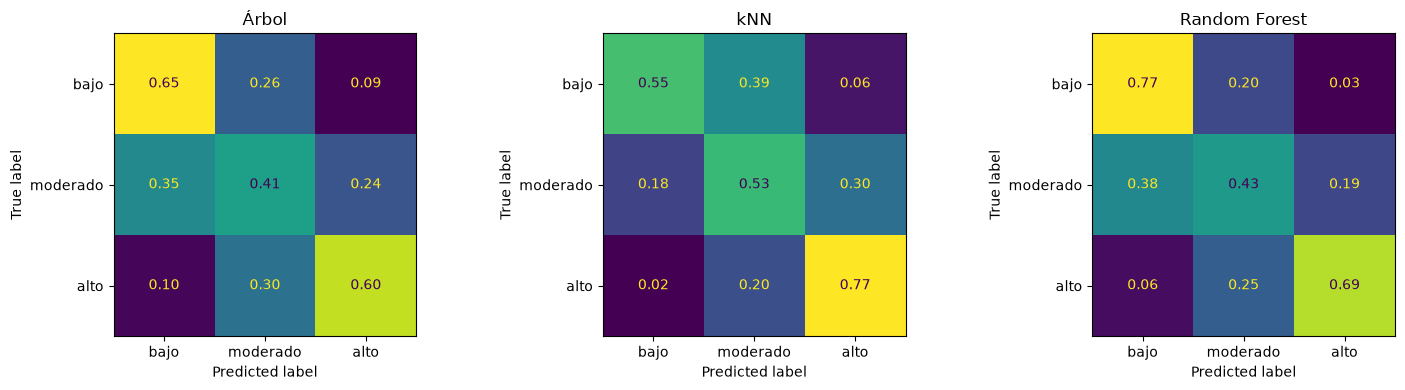

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, busqueda) in zip(axes, [("Árbol", busqueda_arbol), ("kNN", busqueda_knn), ("Random Forest", busqueda_rf)]):
    # cada paciente lo predice el modelo del fold en el que estaba en validación
    y_pred = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=mod.validador, n_jobs=-1)
    # normalize="true": cada fila suma 1, así la diagonal es el recall de cada clase
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["bajo", "moderado", "alto"],
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

**Conclusión.**

| | Árbol | kNN | Random Forest |
|---|---|---|---|
| F1 macro (validación) | 0,541 ± 0,033 | 0,590 ± 0,020 | **0,627 ± 0,023** |
| Recall de riesgo alto | 0,60 | **0,77** | 0,69 |
| Riesgo alto clasificado como bajo | 37 (10 %) | **8 (2 %)** | 21 (6 %) |
| Precisión de riesgo alto | 0,50 | 0,56 | **0,65** |
| Diferencia train-validación | 0,33 | **0,05** | 0,37 |
| Tiempo de entrenamiento (todo el train) | Décimas de segundo | Décimas de segundo | Unos 2 s |

- **Según el criterio acordado, el mejor modelo es Random Forest:** tiene el F1 macro más alto y supera a kNN en los 5 folds, por 0,070, 0,033, 0,042, 0,037 y 0,007. Como la comparación es con los mismos folds, no se trata de un empate y no es necesario desempatar con el recall, aunque en el fold 4 la diferencia es casi nula. Es el candidato de este notebook para la comparación final del grupo.
- **kNN es una alternativa interesante desde el punto de vista clínico:** detecta más pacientes de riesgo alto (0,77) y casi nunca los clasifica como riesgo bajo (2 %), sin sobreajustar. Su principal inconveniente son las falsas alarmas. Conviene tenerlo en cuenta al compararlo con los modelos del resto del grupo.
- **El árbol se descarta por rendimiento**, aunque es el único que se puede interpretar directamente y confirma qué variables utilizan los modelos para decidir.
- **En cuanto a complejidad**, Random Forest es el más costoso de entrenar (segundos frente a décimas de segundo; los valores exactos dependen de la carga del ordenador en cada ejecución) y funciona como una caja negra, aunque la importancia de las variables ayuda a explicarlo. kNN apenas tarda en entrenarse porque solo almacena los pacientes, pero su coste está en la predicción: para cada paciente nuevo tiene que calcular la distancia a todos los del train.